<a href="https://colab.research.google.com/github/jorge-luis01800/metodos_numericos_I/blob/main/Metodo_de_newton_raphson.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Metodo de Newton - Raphson

Por definición, dada una función $f$,\
$p$ es raíz de $f$ si $f(p)=0$\
En esta ocasion usaremos el metodo de **newton-raphson** para aproximar el valor de $p$.



## ¿Cómo funciona?
Supongamos que $f\in C^2[a,b]$ y que $p$ es una raíz de $f$, es decir, $f(p)=0$\
Como no conocemos el valor exacto de $p$, tomemos $p_0\in[a,b]$ como una aproximación inicial, donde suponemos que $|p-p_0|$ es pequeño y que $f'(p_0)\neq 0$ <font color="cyan">**...(*)**</font>\
Ahora, por el teorema de Taylor, podemos expresar $f(p)$ mediante el polinomio de Taylor alrededor de $p_0$:
$$f(p)=f(p_0)+(p-p_0)f'(p_0)+\frac{(p-p_0)^2}{2}f''(\xi)$$
Con $\xi \in [p,p_0]$\
Ahora como $f(p)=0$
$$\implies 0=f(p_0)+(p-p_0)f'(p_0)+\frac{(p-p_0)^2}{2}f''(\xi)$$
Ademas como $|p-p_0|$ es pequeño, en efecto:\
$$|p-p_0|^2 \leq |p-p_0|$$
Luego
$$0\approx f(p_0)+(p-p_0)f'(p_0)$$
Despejando $p$:
$$-f(p_0)\approx (p-p_0)f'(p_0)$$
Ademas por <font color="cyan">**...(*)**</font>
$$\implies -\frac{f(p_0)}{f'(p_0)}\approx p-p_0$$
$$\implies p\approx p_0-\frac{f(p_0)}{f'(p_0)}$$
Es decir, obtenemos una aproximación para $p$, que llamaremos $p_1$
$$p_1=p_0-\frac{f(p_0)}{f'(p_0)}$$
Nuevamente como $p_1$ es una aproximacion, podemos hacer
$$p_2=p_1-\frac{f(p_1)}{f'(p_1)}$$
Análogamente para $n \geq 1$\
$$p_n=p_{n-1}-\frac{f(p_{n-1})}{f'(p_{n-1})}$$
Luego para seleccionar el valor inicial $p_0$ adecuado, nos ayuda el Teorema:\
Sea $f\in C^2[a,b]$. Si $p \in (a, b)$ tal que $f(p) = 0$ ($p$ es raiz) y $f'(p) \neq 0$, entonces existe una $\delta > 0$ tal que el método de Newton genera una sucesión $\{p_n\}_{n=1}^{\infty}$ que converge a $p$ para cualquier aproximación inicial $p_0 \in [p - \delta, p + \delta]$\
Donde la demostracion se sustenta en las hipotesis del teorema de punto fijo, dando el intervalo $[p - \delta, p + \delta]$ que las cumpla

En particular, dada la funcion:
$$f(x)=\cos(x)-x$$
Aproximemos una raiz

Según el teorema:\
Sea $g(x)\in C[a,b]$ tal que $g(x)\in[a,b]$ $\forall x\in[a,b]$.\
Suponga que existe $g'(x)$ en $(a,b)$ para toda $x$ en $[a,b]$ y existe una constante $0<k<1$ tal que:\
$$|g'(x)|\leq k,\quad \forall x\in(a,b)$$
Entonces, para cualquier $p_0\in[a,b]$, la sucesión definida por:\
$$p_n=g(p_{n-1}),\quad n\geq1$$
converge al único punto fijo $p\in[a,b]$.\
Sea:
$$g(x)=\cos x-x$$
en el intervalo $[0,1]$.\
Como $g$ es continua en $[0,1]$, podemos encontrar sus valores máximo y mínimo\
Si
$$g'(x)=-\sin x-1=0$$
Como $\sin x\geq0$ para todo $x\in[0,1]$, esta ecuación no tiene soluciones en el intervalo, por lo que nuestros candidatos a max/min son los extremos del intervalo.
Sean:
$$g(0)=\cos 0-0=1$$
$$g(1)=\cos 1-1\approx-0.4596976941$$
Ademas, la función es decreciente\
Por lo tanto, el máximo se alcanza en $x=0$ y el mínimo absoluto se alcanza en $x=1$\
Así:\
$$-0.4596976941\leq g(x)\leq1,\quad\forall x\in[0,1]$$
Pero
$$g(1)\notin[0,1]$$
Por lo tanto, no se cumple la primera hipótesis del teorema de punto fijo en el intervalo $[0,1]$\
Pero, analicemos la segunda condición\
**Acotemos la derivada.**\
Sea:\
$$h(x)=-\sin x-1$$
Si
$$h'(x)=-\cos x=0$$
$$\implies \cos x=0$$
Dado que no tiene soluciones en $[0,1]$ nos quedan como candidatos los extremos del intervalo:
$$h(0)=-\sin 0-1=-1$$
$$h(1)=-\sin 1-1\approx-1.8414709848$$
Ademas, la funcion es decreciente.\
Así, el máximo absoluto se alcanza en $x=0$ y el mínimo absoluto se alcanza en $x=1$\
Por lo tanto:\
$$-1.8414709848\leq h(x)\leq-1,\quad\forall x\in[0,1]$$
Dado que $h(x)=g'(x)$, tenemos:\
$$-1.8414709848\leq g'(x)\leq-1,\quad\forall x\in[0,1]$$
Luego
$$|g'(x)|\leq1.8414709848,\quad\forall x\in[0,1]$$
Es decir, no se cumple la segunda hipotesis, pero la derivada sigue siendo pequeña\
Asi, tomemos
$$p_0=\frac{\pi}{4}\in [0,1]$$

Definamos la funcion y su derivada:

In [12]:
def f(x):
    return np.cos(x) - x
def df(x):
    return -np.sin(x) -1

Traemos algunas bibloitecas de funciones y constantes:

In [13]:
import numpy as np
import matplotlib.pyplot as plt

Definimos algunos valores necesarios para nuestro programa

In [14]:
p0 = np.pi/4 #Valor inicial
TOL = 0.000001 #Tolerancia
N_0 = 200 #Numero maximo de iteraciones

In [15]:
#Iniciamos el conteo de iteraciones en 1
i = 1
#Imprimimos la parte inicial de la tabla
print(f"n iter\t\t P_n-1 \t\t P_n \t\t |P_n - P_n-1|")
#Iniciamos el ciclo de iteraciones
while i<=N_0:
    p=p0-f(p0)/df(p0)  #Calculamos el siguiente valor
    if abs(p-p0)<TOL:    #Verificamos la tolerancia
        raiz=p           #Conservamos la mejor aproximacion
        print("{0} \t\t {1:6.6f} \t {2:6.6f} \t {3:6.6f}".format(
            i, p0, p, abs(p-p0)))
        print("")
        print(f"La raiz aproximada de f es: {raiz}")
        break
    else:
        error=abs(p-p0)  # Guardamos el error para mandar a imprimir
        print("{0} \t\t {1:6.6f} \t {2:6.6f} \t {3:6.6f}".format(
            i, p0, p, error))
        i=i+1 #Avanzamos de iteracion
        p0=p  # Actualizamos p0
else:
    print(f"El método falló después de {N_0} iteraciones, N_0 = {N_0}")


n iter		 P_n-1 		 P_n 		 |P_n - P_n-1|
1 		 0.785398 	 0.739536 	 0.045862
2 		 0.739536 	 0.739085 	 0.000451
3 		 0.739085 	 0.739085 	 0.000000

La raiz aproximada de f es: 0.7390851332151611


Graficamente

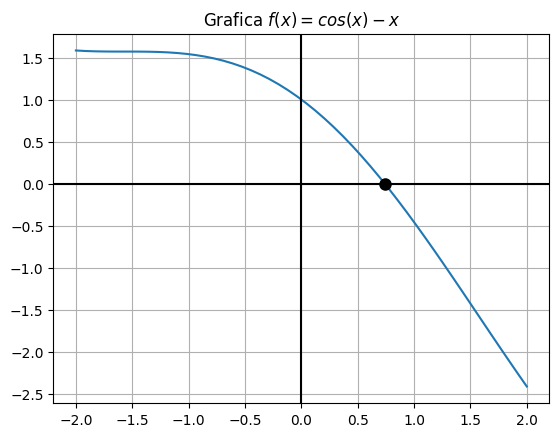

In [16]:
x=np.linspace(-2,2,50) #Generamos 50 particiones de -2 a 2
plt.plot(x,f(x)) #Dibujamos la funcion
plt.title("Grafica $f(x)=cos(x) - x$") #Nombramos la grafica
plt.axhline(0, color='black') #Dibujamos el eje y
plt.axvline(0, color='black') #Dibujamos el eje x
plt.plot(raiz, 0, 'o', color='black', markersize=8) #Dibujamos el punto
plt.grid()#cuadricula